# Homework # 4 Naive BAYES Classifier

### Instructor - Dr. Uma Gajendragadkar

### Problem - Design and develop Machine learning model to predict Diabetes using Naive Bayes Algorithm. 

### Dataset - Diabetes dataset

This dataset consists of 768 observations & 8 numerical independent variables.
Dependent and target variable is OUTCOME. 1 means diabetes test result being positive, 0 means indicates negative.

Pregnancies: Number of Times Being Pregnant

Glucose: Plasma Glucose Concentration (a 2 hours in an oral glucose tolerance test)

BloodPressure: Diastolic Blood Pressure (mm Hg)

SkinThickness: Triceps Skin Fold Thickness (mm)

Insulin: 2-Hour Serum Insulin (mu U/ml)

BMI: Body Mass Index (weight in kg/(height in m)^2)

DiabetesPedigreeFunction: Diabetes Pedigree Function

Age: Age

Outcome: Class variable ( 0 - 1)



In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_validate
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 500)
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot  as plt
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn import preprocessing
from sklearn.naive_bayes import GaussianNB

Step 1 - Write code to Read data from dataset into pandas dataframe

In [3]:
df = pd.read_csv('diabetes.csv')

Step 2 - a) Write code to display dataset info 
b) Print 10 rows from dataset.

In [4]:
print(df.head(10), "\n")
print(df.info())


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin    BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0 33.600                     0.627   50        1
1            1       85             66             29        0 26.600                     0.351   31        0
2            8      183             64              0        0 23.300                     0.672   32        1
3            1       89             66             23       94 28.100                     0.167   21        0
4            0      137             40             35      168 43.100                     2.288   33        1
5            5      116             74              0        0 25.600                     0.201   30        0
6            3       78             50             32       88 31.000                     0.248   26        1
7           10      115              0              0        0 35.300                     0.134   29        0
8         

Step 3 - Write code to remove Pregnancy column 

In [9]:
df.drop(['Pregnancies'], axis=1, inplace=True)

Step 4 - Write code to display info of dataset and check shape of dataset.

In [5]:
print(df.info())
print("\nShape:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Shape: (768, 9)


Step 5 - Write code to clean data

In [6]:
print("NaN values:\n", df.isnull().sum(), "\n")
print("0 values:\n", (df==0).sum())

NaN values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64 

0 values:
 Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [7]:
fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[fix] = df[fix].replace(0, np.nan)
df[fix] = df[fix].fillna(df[fix].mean())
df.head(20)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.000,72.000,35.000,155.548,33.600,0.627,50,1
1,1,85.000,66.000,29.000,155.548,26.600,0.351,31,0
2,8,183.000,64.000,29.153,155.548,23.300,0.672,32,1
3,1,89.000,66.000,23.000,94.000,28.100,0.167,21,0
4,0,137.000,40.000,35.000,168.000,43.100,2.288,33,1
5,5,116.000,74.000,29.153,155.548,25.600,0.201,30,0
6,3,78.000,50.000,32.000,88.000,31.000,0.248,26,1
7,10,115.000,72.405,29.153,155.548,35.300,0.134,29,0
8,2,197.000,70.000,45.000,543.000,30.500,0.158,53,1
9,8,125.000,96.000,29.153,155.548,32.457,0.232,54,1


Step 6 - Split data into training and testing sets ( 80: 20 ratio)

In [8]:
target = df['Outcome']
inputs = df.drop('Outcome', axis=1)
X_train, X_test, y_train, y_test = train_test_split(inputs, target, test_size=0.2, random_state=1)

print(len(X_train), len(X_test), len(inputs))


print(len(X_train) / len(inputs)) 
print(len(X_test) / len(inputs)) 

614 154 768
0.7994791666666666
0.20052083333333334


#### **Step #7: Initialize your model**




In [9]:
model = GaussianNB()

#### **Step #8: Fit your model, test on the testing data, and create a visualization if applicable**

In [10]:
model.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


Step 9 - Predict using model on test data

In [11]:
pred = np.array(model.predict(X_test))
pred_probability = np.array(model.predict_proba(X_test))

print(pred[:20])
for i in range(1,20):
    print(pred_probability[i][0], end="\n ")

[0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 1 0 0 0 0]
0.8987756981565689
 0.9687683851692649
 0.9313149671177677
 0.861692656255652
 0.9097358499547938
 0.8521190185662846
 0.9940004120910765
 0.8789256293574695
 0.8761295997012679
 0.32461728887483315
 0.9759171711349998
 1.6062329010290513e-06
 0.1452239402247237
 0.3725272357151467
 0.09346222238977868
 0.8951509876286667
 0.814873194542963
 0.9878062216318357
 0.9665691785785476
 

Step 10 -  Find accuracy of model

In [12]:
accuracy = accuracy_score(y_test, pred)
print("Accuracy:", round(accuracy*100, 4), "%")

Accuracy: 76.6234 %


Step 11 - Confusion Matrix

Confusion matrix:
 [[84 15]
 [21 34]]


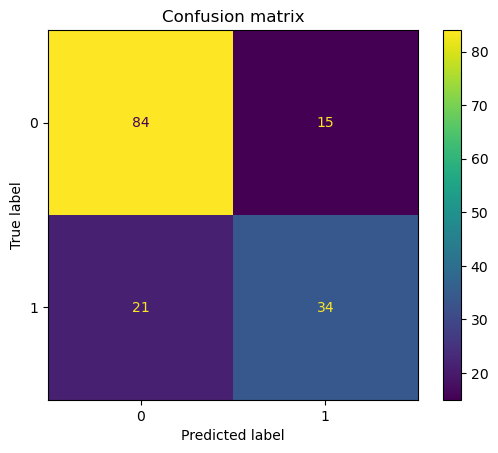

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test, pred)
print("Confusion matrix:\n", cm)

cm_disp = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_disp.plot()
plt.title('Confusion matrix')
plt.show()